# Evaluating Models and Decoders

Decoding a stimulus from population activity, or a behavioural variable from a trained network, ends with an evaluation. This notebook decodes simulated neural data and evaluates the decoders with:

| Question | Function |
|---|---|
| Which classes are confused? | `confusion_matrix` |
| How well does a score separate two classes? | `roc_curve`, `precision_recall_curve` |
| Would more data help? | `learning_curve` |
| Are a regression model's errors structured? | `residual_plot` |

The decoders are written in a few lines of NumPy, so the notebook has no machine-learning dependency; the plotting functions only need labels, predictions and scores.

## 1. Setup and Data

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import braintools

plt.rcParams["figure.dpi"] = 90
rng = np.random.default_rng(3)

30 orientation-tuned neurons with preferred orientations spread over 180°, recorded for only 30 ms on each trial, so that each neuron fires about 0.2 spikes per trial and decoding is far from perfect. The stimulus is one of four orientations (0°, 45°, 90°, 135°); responses are Poisson spike counts. Orientation is circular with period 180°.

In [2]:
n_neurons, window = 30, 0.03
prefs = np.linspace(0, 180, n_neurons, endpoint=False)
classes = np.array([0.0, 45.0, 90.0, 135.0])

def responses(stim_deg):
    d = np.abs((stim_deg[:, None] - prefs[None, :] + 90) % 180 - 90)      # circular distance in degrees
    rate = 3 + 15 * np.exp(-d ** 2 / (2 * 25 ** 2))                       # Hz
    return rng.poisson(rate * window).astype(float)

y = rng.integers(0, 4, 800)
X = responses(classes[y])
X_train, y_train, X_test, y_test = X[:500], y[:500], X[500:], y[500:]
print("trials:", X.shape, " mean spikes per neuron and trial:", X.mean().round(2))

trials: (800, 30)  mean spikes per neuron and trial: 0.25


## 2. Multi-class Decoding and the Confusion Matrix

A linear decoder fitted by ridge regression onto one-hot targets; the predicted class is the largest output.

test accuracy: 0.763 (chance 0.25)


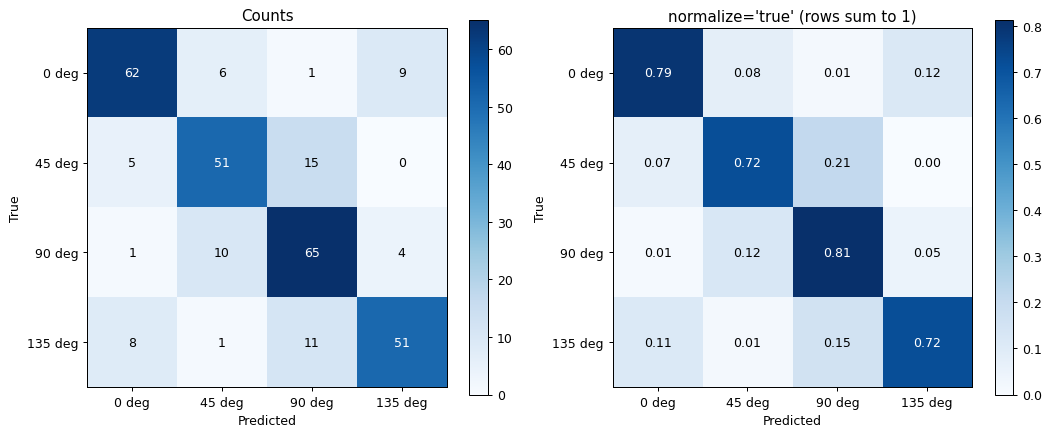

In [3]:
def fit_linear(X, Y, lam=10.0):
    Xb = np.c_[X, np.ones(len(X))]
    return np.linalg.solve(Xb.T @ Xb + lam * np.eye(Xb.shape[1]), Xb.T @ Y)

def predict(W, X):
    return np.c_[X, np.ones(len(X))] @ W

W = fit_linear(X_train, np.eye(4)[y_train])
scores = predict(W, X_test)
y_pred = scores.argmax(1)
print(f"test accuracy: {np.mean(y_pred == y_test):.3f} (chance 0.25)")

names = [f"{c:g} deg" for c in classes]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
braintools.visualize.confusion_matrix(y_test, y_pred, labels=names, ax=ax[0], title="Counts")
braintools.visualize.confusion_matrix(y_test, y_pred, labels=names, normalize="true", ax=ax[1],
                                      title="normalize='true' (rows sum to 1)")
plt.tight_layout(); plt.show()

Rows are true classes, columns predicted classes. With `normalize='true'` each row sums to 1, so the diagonal is the recall of each class; `'pred'` normalizes columns (precision) and `'all'` the whole matrix. Errors fall mostly on **neighbouring** orientations (45° apart) and only rarely (about 1 %) on the orthogonal one, as expected from the overlapping tuning curves; 0° and 135° count as neighbours too, because orientation wraps around at 180°.

## 3. Binary Scores: ROC and Precision–Recall

Now a detection task: is the stimulus 90°? The decoder output for that class is a continuous score. `roc_curve` plots the true-positive against the false-positive rate over all thresholds and reports the area under the curve (AUC); `precision_recall_curve` plots precision against recall and reports the average precision (AP), $\sum_k (R_k - R_{k-1}) P_k$. Here only a quarter of the trials are positive.

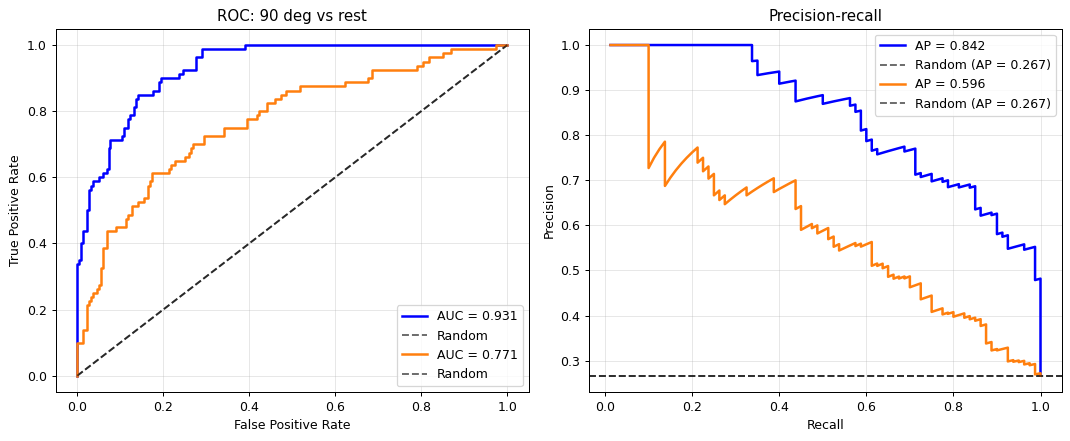

P(score_pos > score_neg) = 0.931


In [4]:
is_90 = (y_test == 2).astype(int)
score_90 = scores[:, 2]
noisy_score = score_90 + rng.normal(0, 0.4, len(score_90))       # a worse decoder, for comparison

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
braintools.visualize.roc_curve(is_90, score_90, ax=ax[0], title="ROC: 90 deg vs rest")
braintools.visualize.roc_curve(is_90, noisy_score, ax=ax[0], color="C1", title="ROC: 90 deg vs rest")
braintools.visualize.precision_recall_curve(is_90, score_90, ax=ax[1], title="Precision-recall")
braintools.visualize.precision_recall_curve(is_90, noisy_score, ax=ax[1], color="C1", title="Precision-recall")
plt.tight_layout(); plt.show()

# the AUC equals the probability that a random positive outscores a random negative
pos, neg = score_90[is_90 == 1], score_90[is_90 == 0]
print(f"P(score_pos > score_neg) = {np.mean(pos[:, None] > neg[None, :]):.3f}")

Each call adds a curve with its own legend entry (AUC or AP) and draws the chance level again: the diagonal for ROC, the fraction of positives (here about 0.25) for precision–recall. The printed probability that a positive trial outscores a negative one equals the decoder's AUC, a useful way to read the number.

ROC curves do not depend on the class balance, precision–recall curves do: with rare positives, a small false-positive rate still produces many false positives relative to the true ones, which lowers precision. For imbalanced detection problems the PR curve is the more informative of the two.

## 4. Learning Curves

How does accuracy depend on the number of training trials? We train on random subsets of increasing size, 20 times each, and evaluate on the held-out trials. `learning_curve` accepts 1-D scores or 2-D arrays `(sizes, repetitions)`, in which case it plots the mean with a ± 1 standard deviation band.

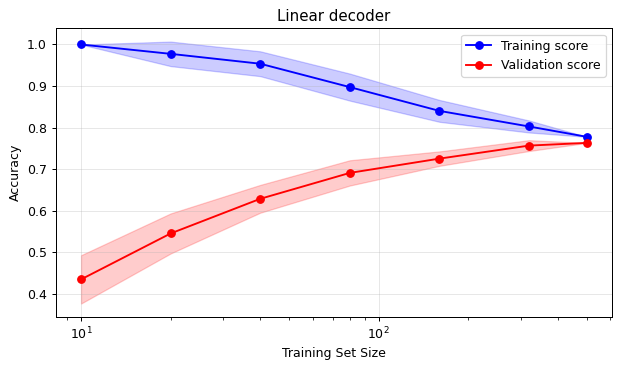

validation accuracy by training size: {10: 0.435, 20: 0.546, 40: 0.629, 80: 0.691, 160: 0.726, 320: 0.757, 500: 0.763}


In [5]:
sizes = np.array([10, 20, 40, 80, 160, 320, 500])
train_acc = np.zeros((len(sizes), 20))
test_acc = np.zeros((len(sizes), 20))
for i, m in enumerate(sizes):
    for r in range(20):
        idx = rng.choice(500, m, replace=False)
        W_m = fit_linear(X_train[idx], np.eye(4)[y_train[idx]])
        train_acc[i, r] = np.mean(predict(W_m, X_train[idx]).argmax(1) == y_train[idx])
        test_acc[i, r] = np.mean(predict(W_m, X_test).argmax(1) == y_test)

fig, ax = plt.subplots(figsize=(7, 4.2))
braintools.visualize.learning_curve(sizes, train_acc, test_acc, ax=ax, title="Linear decoder")
ax.set_xscale("log"); ax.set_ylabel("Accuracy")
plt.tight_layout(); plt.show()
print("validation accuracy by training size:", dict(zip(sizes.tolist(), test_acc.mean(1).round(3).tolist())))

With few trials the decoder fits its training set perfectly but generalizes poorly (a large gap, i.e. overfitting); with more data the curves approach each other. The validation curve is still rising slowly at 500 trials, so more data would help a little.

## 5. Regression Residuals

Finally, a continuous variable: decoding the stimulus **contrast** from the total spike count of the population. With Poisson spiking, the variance of the count grows with its mean, so the residuals of a least-squares fit are **heteroscedastic**: they spread more at high contrast. `residual_plot(y_true, y_pred)` shows residuals against predictions with a zero line:

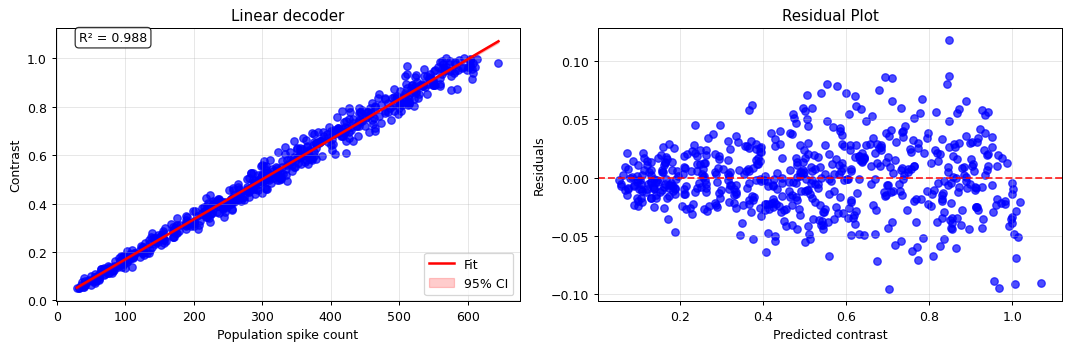

residual std for predictions < 0.3: 0.0161, > 0.7: 0.0379


In [6]:
contrast = rng.uniform(0.05, 1.0, 600)
total = rng.poisson(600 * contrast)                       # population spike count grows with contrast
slope, intercept = np.polyfit(total, contrast, 1)
pred = slope * total + intercept

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
braintools.visualize.regression_plot(total, contrast, ax=ax[0], xlabel="Population spike count", ylabel="Contrast",
                                     title="Linear decoder")
braintools.visualize.residual_plot(contrast, pred, ax=ax[1], xlabel="Predicted contrast")
plt.tight_layout(); plt.show()
lo, hi = pred < 0.3, pred > 0.7
print(f"residual std for predictions < 0.3: {np.std(contrast[lo] - pred[lo]):.4f}, > 0.7: {np.std(contrast[hi] - pred[hi]):.4f}")

The residuals fan out with the prediction: the decoder is less precise at high contrast, in absolute terms, as the Poisson model predicts (the relative error, std/mean, still decreases). A plot of residuals against predictions shows such structure immediately, whereas a single summary like $R^2$ hides it.

## Summary

- `confusion_matrix(y_true, y_pred)` with `normalize='true'`, `'pred'` or `'all'`; rows are true classes.
- `roc_curve` reports the AUC (the probability that a positive outscores a negative); `precision_recall_curve` reports the step-wise average precision and the chance level, and is the better choice for rare positives. Several curves can share one axis.
- `learning_curve` takes `(sizes, repetitions)` score arrays and shows mean ± std; the gap between training and validation scores indicates overfitting.
- `residual_plot` reveals structure in a regression model's errors, such as curvature or heteroscedasticity.